# ДЗ 2. Прогноз продаж товара

Построены прогнозы продаж декоративных птиц ASSORTED COLOUR BIRD ORNAMENT за день, неделю и месяц. Использован товар 84879 из ДЗ1. Проведено сравнение четырёх моделей и оценено изменение ошибки на разных горизонтах прогнозирования.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing

## Данные из ДЗ1

В файле `data/daily_sales.csv` лежат чистые продажи за каждый полный день. Покупки прибавляются, возвраты вычитаются в день оформления. Списание повреждённого товара исключено. Ноль означает, что за день в выгрузке не зарегистрировали продаж или возвратов этого товара.

Дневные значения суммируются за недели и месяцы. В анализ включены только полные периоды.

4 августа по накладной 562439 зарегистрирована покупка 2 880 штук. Продажи за день составили 3 359 штук, за ту неделю - 3 800, за август - 6 552. Это нехарактерная, но зарегистрированная покупка, поэтому она сохранена в ряду.

In [2]:
def load_series(path):
    daily = pd.read_csv(path, parse_dates=['date']).set_index('date')['sales']
    assert daily.index.is_unique and daily.index.is_monotonic_increasing
    daily = daily.asfreq('D')
    assert daily.notna().all(), 'В дневном ряду есть пропуск'

    weeks = daily.resample('W-SUN')
    weekly = weeks.sum()[weeks.count() == 7]
    months = daily.resample('ME')
    monthly = months.sum()
    monthly = monthly[months.count() == monthly.index.days_in_month]
    return {'День': daily, 'Неделя': weekly, 'Месяц': monthly}

series = load_series('data/daily_sales.csv')
pd.DataFrame([[name, len(s), s.index[0].date(), s.index[-1].date()] for name, s in series.items()], columns=['Частота', 'Полных периодов', 'Первая дата', 'Последняя дата'])

,Частота,Полных периодов,Первая дата,Последняя дата
0,День,373,2010-12-01,2011-12-08
1,Неделя,52,2010-12-12,2011-12-04
2,Месяц,12,2010-12-31,2011-11-30


## Проверка прогноза

Для проверки использованы последние 28 дней, 8 недель и 4 месяца. Внутри каждой частоты все модели прогнозируют одни и те же даты. Горизонт показывает число шагов между концом обучения и датой прогноза. Например, для прогноза на 8 декабря с горизонтом 7 дней используются продажи по 1 декабря включительно.

Обучение начинается с первой даты ряда. При переходе к следующей дате прогноза в обучение добавляется ещё одно известное значение. Это проверка с расширяющимся окном. В таблице показано первое, самое короткое окно обучения для каждой частоты.

Для каждого горизонта обучение заканчивается ровно за нужное число шагов до проверяемой даты. Между концом обучения и этой датой модель строит весь прогноз. Средняя ошибка рассчитывается по последнему шагу каждого такого прогноза.

In [3]:
horizons = {'День': [1, 7, 31, 61], 'Неделя': [1, 4, 8], 'Месяц': [1, 2]}
test_size = {'День': 28, 'Неделя': 8, 'Месяц': 4}

rows = []
for name, s in series.items():
    n = test_size[name]
    first_train = s.iloc[:len(s) - n - max(horizons[name]) + 1]
    assert len(first_train) > 0 and len(s.iloc[-n:]) == n
    rows.append([name, ', '.join(map(str, horizons[name])), len(first_train),
                 first_train.index[-1].date(), s.index[-n].date(), s.index[-1].date(), n])

pd.DataFrame(rows, columns=['Частота', 'Горизонты', 'Точек обучения', 'Обучение по',
                            'Проверка с', 'Проверка по', 'Дат проверки'])

,Частота,Горизонты,Точек обучения,Обучение по,Проверка с,Проверка по,Дат проверки
0,День,"1, 7, 31, 61",285,2011-09-11,2011-11-11,2011-12-08,28
1,Неделя,"1, 4, 8",37,2011-08-21,2011-10-16,2011-12-04,8
2,Месяц,"1, 2",7,2011-06-30,2011-08-31,2011-11-30,4


## Модели

**Наивный прогноз.** В ДЗ1 был заметен недельный ритм. Для дневного ряда повторяется последняя известная неделя. Для недель и месяцев используется последнее известное значение.

**Простое экспоненциальное сглаживание.** После каждого наблюдения обновляется уровень продаж. Коэффициент сглаживания модель подбирает на обучающей части. На все будущие даты прогноз равен последнему сглаженному уровню.

In [4]:
def naive_forecast(train, dates, freq):
    period = 7 if freq == 'День' else 1
    last_period = train.iloc[-period:].to_numpy()
    return np.resize(last_period, len(dates))

def smooth_forecast(train, dates, freq):
    model = SimpleExpSmoothing(train.to_numpy(), initialization_method='estimated')
    return model.fit(method='least_squares').forecast(len(dates))

**Методы Холта и Холта-Уинтерса.** Для учёта изменения общего уровня продаж используются модели с трендом. Для недель и месяцев выбрана модель Холта с линейным трендом. Для дней используется модель Холта-Уинтерса с сезонностью периода 7. Сезонная прибавка складывается с уровнем и трендом. Такой вариант допускает нулевые продажи.

Все коэффициенты сглаживания оцениваются по обучающей выборке. По 12 месячным значениям годовую сезонность оценить трудно, поэтому для месяцев учтён только тренд.

In [5]:
def trend_forecast(train, dates, freq):
    seasonal = 'add' if freq == 'День' else None
    period = 7 if freq == 'День' else None
    model = ExponentialSmoothing(
        train.to_numpy(), trend='add', seasonal=seasonal,
        seasonal_periods=period, initialization_method='estimated')
    return model.fit(method='least_squares').forecast(len(dates))

**Градиентный бустинг.** Для дневного прогноза используются продажи за предыдущий день, продажи неделю назад, среднее за прошлую неделю и день недели. Для недельного и месячного прогноза используются последнее значение и среднее двух последних периодов.

Модель обучается предсказывать один шаг. При прогнозировании на несколько шагов полученный прогноз добавляется в конец истории, после чего рассчитываются признаки для следующего шага. Для всех частот используются 50 деревьев глубиной до двух. Настройки одинаковы на всех горизонтах.

In [6]:
def sales_features(past, date, freq):
    if freq == 'День':
        return [past[-1], past[-7], np.mean(past[-7:]), date.dayofweek]
    return [past[-1], np.mean(past[-2:])]

def boost_forecast(train, dates, freq):
    past = train.to_list()
    window = 7 if freq == 'День' else 2
    x = [sales_features(past[i-window:i], train.index[i], freq) for i in range(window, len(past))]
    model = GradientBoostingRegressor(n_estimators=50, max_depth=2,
                                      learning_rate=0.05, random_state=42)
    model.fit(x, past[window:])

    predictions = []
    for date in dates:
        features = sales_features(past, date, freq)
        value = model.predict([features])[0]
        past.append(value)
        predictions.append(value)
    return predictions

## Прогнозы

Для каждой тестовой даты конец обучения определяется на нужное число шагов раньше. Модель получает историю до этой границы и список будущих дат. Для оценки используется последний шаг полученного прогноза.

Все промежуточные шаги сохраняются в файле forecast_paths.csv. Таблица forecasts.csv содержит конечные шаги, по которым рассчитываются основные метрики.

In [7]:
models = {'Наивный': naive_forecast, 'Сглаживание': smooth_forecast,
          'Бустинг': boost_forecast, 'Холт / Холт-Уинтерс': trend_forecast}

def check_forecasts(s, freq, steps, n_test):
    rows = []
    for h in steps:
        for i in range(len(s) - n_test, len(s)):
            start = i - h + 1
            train = s.iloc[:start]
            dates = s.index[start:i + 1]
            for name, forecast in models.items():
                prediction = forecast(train, dates, freq)
                assert len(prediction) == h and np.isfinite(prediction).all()
                for step, (date, value) in enumerate(zip(dates, prediction), start=1):
                    rows.append([freq, h, name, train.index[-1], date,
                                 s.loc[date], value, step])
    return rows

rows = []
for freq, s in series.items():
    rows.extend(check_forecasts(s, freq, horizons[freq], test_size[freq]))

forecast_paths = pd.DataFrame(rows, columns=['Частота', 'Горизонт', 'Модель', 'Конец обучения',
                                             'Дата прогноза', 'Факт', 'Прогноз', 'Шаг'])
forecasts = forecast_paths[forecast_paths['Шаг'] == forecast_paths['Горизонт']].drop(columns='Шаг')
results_dir = Path('results')
results_dir.mkdir(exist_ok=True)
forecast_paths.to_csv(results_dir / 'forecast_paths.csv', index=False, encoding='utf-8-sig')
forecasts.to_csv(results_dir / 'forecasts.csv', index=False, encoding='utf-8-sig')
forecasts.head(8).round(1)

,Частота,Горизонт,Модель,Конец обучения,Дата прогноза,Факт,Прогноз
0,День,1,Наивный,2011-11-10,2011-11-11,100,80.0
1,День,1,Сглаживание,2011-11-10,2011-11-11,100,93.4
2,День,1,Бустинг,2011-11-10,2011-11-11,100,114.9
3,День,1,Холт / Холт-Уинтерс,2011-11-10,2011-11-11,100,103.4
4,День,1,Наивный,2011-11-11,2011-11-12,0,0.0
5,День,1,Сглаживание,2011-11-11,2011-11-12,0,93.5
6,День,1,Бустинг,2011-11-11,2011-11-12,0,36.2
7,День,1,Холт / Холт-Уинтерс,2011-11-11,2011-11-12,0,38.7


## Оценка качества

Основная метрика - **MAE**. Это средняя абсолютная ошибка в штуках. По ней выбирается лучшая модель для каждой частоты и горизонта. **RMSE** тоже измеряется в штуках, но сильнее реагирует на крупные промахи.

Дневные и месячные суммы различаются по масштабу. Для сравнения относительных ошибок рассчитана **WAPE**. Сумма абсолютных ошибок делится на сумму фактических продаж по модулю. Результат выражается в процентах. Так в расчёте остаются и дни с нулевыми продажами. Для всех трёх метрик меньшее значение лучше.

In [8]:
def get_scores(group):
    error = group['Факт'] - group['Прогноз']
    mae = error.abs().mean()
    rmse = np.sqrt((error ** 2).mean())
    wape = 100 * error.abs().sum() / group['Факт'].abs().sum()
    return [len(group), mae, rmse, wape]

def score_forecasts(forecasts):
    keys = ['Частота', 'Горизонт', 'Модель']
    rows = []
    for key, group in forecasts.groupby(keys, sort=False):
        rows.append([*key, *get_scores(group)])
    return pd.DataFrame(rows, columns=keys + ['Дат проверки', 'MAE, шт.', 'RMSE, шт.', 'WAPE, %'])

scores = score_forecasts(forecasts)
scores.to_csv(results_dir / 'metrics.csv', index=False, encoding='utf-8-sig')
scores.round(1)

,Частота,Горизонт,Модель,Дат проверки,"MAE, шт.","RMSE, шт.","WAPE, %"
0,День,1,Наивный,28,140.0,236.3,95.3
1,День,1,Сглаживание,28,100.3,135.4,68.3
2,День,1,Бустинг,28,88.3,126.4,60.1
3,День,1,Холт / Холт-Уинтерс,28,97.7,131.2,66.5
4,День,7,Наивный,28,140.0,236.3,95.3
5,День,7,Сглаживание,28,101.0,136.0,68.8
6,День,7,Бустинг,28,92.1,129.0,62.7
7,День,7,Холт / Холт-Уинтерс,28,96.8,130.8,65.9
8,День,31,Наивный,28,115.4,160.1,78.6
9,День,31,Сглаживание,28,101.8,141.8,69.3


## Факт и прогноз

На графиках представлены прогнозы каждой модели на 61 день, 8 недель и 2 месяца. Для каждого графика использована одна дата конца обучения. Все точки справа от вертикальной линии предсказаны в этот день. В таблице метрик выше учтены все даты проверки.

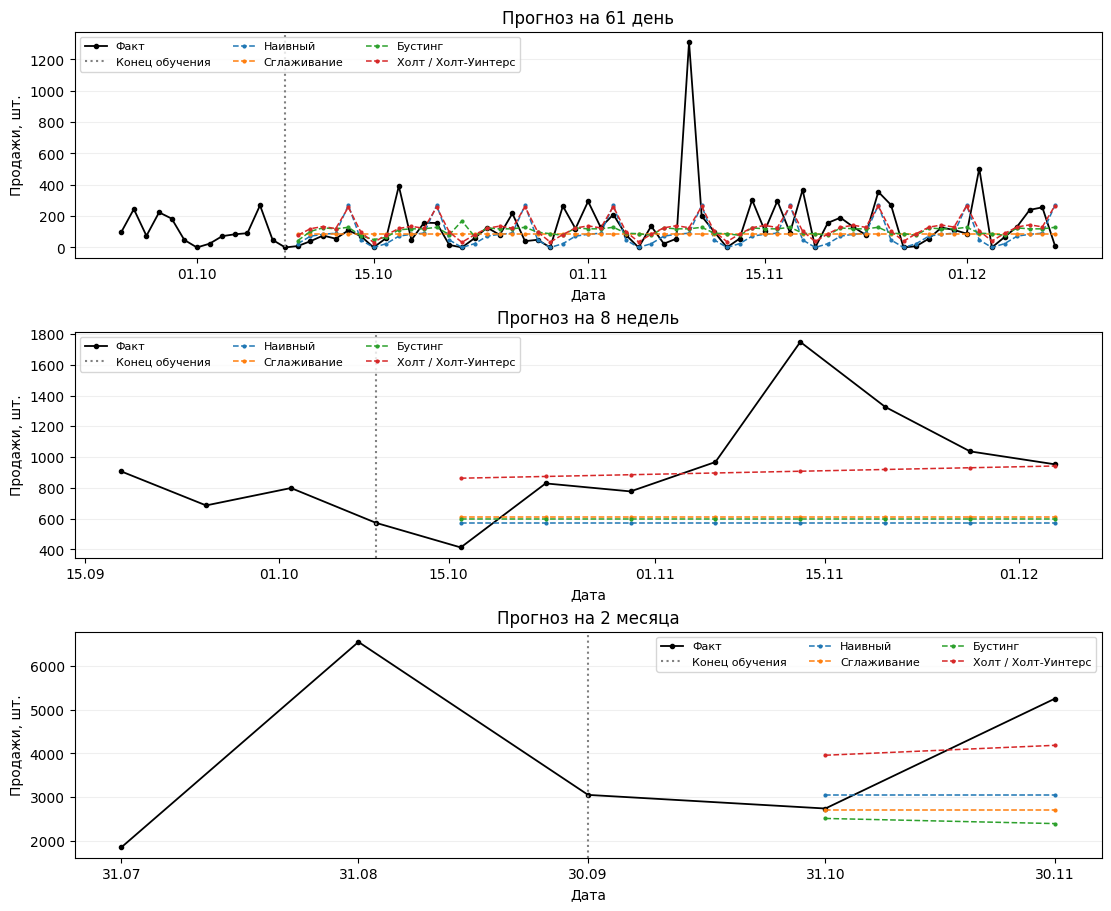

In [9]:
def plot_forecast(ax, s, freq, h, history, title):
    train = s.iloc[:-h]
    test = s.iloc[-h:]
    observed = s.iloc[-(h + history):]
    ax.plot(observed.index, observed, 'o-', color='black', linewidth=1.3,
            markersize=3, label='Факт')
    ax.axvline(train.index[-1], color='gray', linestyle=':', label='Конец обучения')
    for name, forecast in models.items():
        values = forecast(train, test.index, freq)
        ax.plot(test.index, values, '.--', linewidth=1.1, markersize=4, label=name)

    ax.set(title=title, xlabel='Дата', ylabel='Продажи, шт.')
    if freq == 'Месяц':
        ax.set_xticks(observed.index)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d.%m'))
    ax.grid(axis='y', alpha=0.2)
    ax.legend(ncol=3, fontsize=8)

fig, axes = plt.subplots(3, 1, figsize=(11, 9), layout='constrained')
titles = ['Прогноз на 61 день', 'Прогноз на 8 недель', 'Прогноз на 2 месяца']
for ax, (freq, s), history, title in zip(axes, series.items(), [14, 4, 3], titles):
    plot_forecast(ax, s, freq, max(horizons[freq]), history, title)
plt.show()

Объём продаж 9 ноября составил 1 312 штук. По данным на 8 октября ни одна модель не ожидала такого скачка. Наивный прогноз на этот день дал 91 штуку, сглаживание - 89, бустинг - 119, Холт-Уинтерс - 126. На недельном графике тот же пик заметен в неделе, которая закончилась 13 ноября.

На месячном графике сглаживание близко к факту в октябре. На ноябрь оно дало тот же прогноз около 2 706 штук, а продажи выросли до 5 254. Модель с постоянным уровнем пропустила этот рост.


## Сравнение по горизонтам

На каждом графике своя шкала продаж. Высота столбца показывает средний промах в штуках за один день, одну неделю или один месяц. Модели сравниваются внутри каждой группы столбцов.

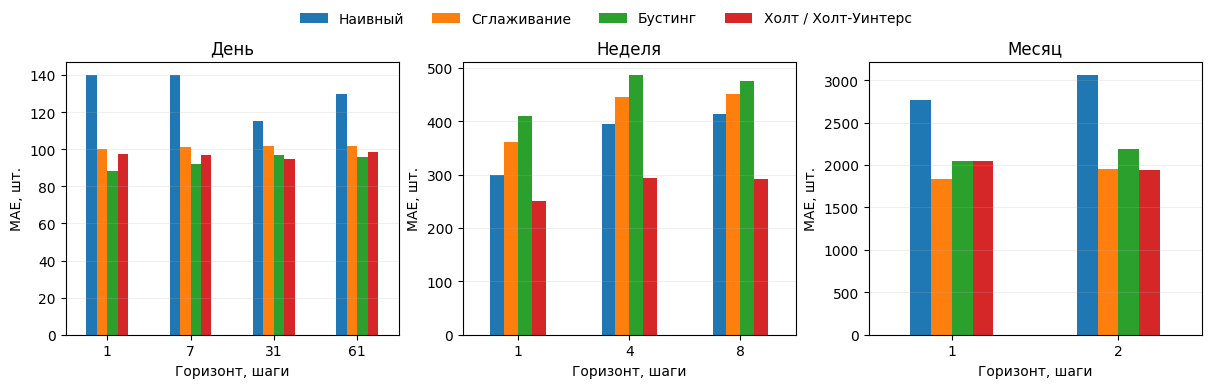

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout='constrained')
for ax, freq in zip(axes, series):
    table = scores[scores['Частота'] == freq].pivot(
        index='Горизонт', columns='Модель', values='MAE, шт.')
    table[list(models)].plot.bar(ax=ax, rot=0, legend=False)
    ax.set(title=freq, xlabel='Горизонт, шаги', ylabel='MAE, шт.')
    ax.grid(axis='y', alpha=0.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper center', ncol=4, frameon=False)
plt.show()

In [11]:
best = scores.loc[scores.groupby(['Частота', 'Горизонт'], sort=False)['MAE, шт.'].idxmin()]
best[['Частота', 'Горизонт', 'Модель', 'MAE, шт.', 'RMSE, шт.', 'WAPE, %']].round(1)

,Частота,Горизонт,Модель,"MAE, шт.","RMSE, шт.","WAPE, %"
2,День,1,Бустинг,88.3,126.4,60.1
6,День,7,Бустинг,92.1,129.0,62.7
11,День,31,Холт / Холт-Уинтерс,94.9,134.6,64.6
14,День,61,Бустинг,96.1,133.4,65.4
19,Неделя,1,Холт / Холт-Уинтерс,249.8,377.9,24.8
23,Неделя,4,Холт / Холт-Уинтерс,293.1,402.9,29.1
27,Неделя,8,Холт / Холт-Уинтерс,291.7,396.8,29.0
29,Месяц,1,Сглаживание,1831.1,2535.5,41.6
35,Месяц,2,Холт / Холт-Уинтерс,1943.2,2338.2,44.2


## Почему дневная ошибка высокая

Рассмотрены ошибки бустинга на горизонте один день. В проверку включены 28 дат с 11 ноября по 8 декабря. Выделены пять самых больших ошибок и оценён их вклад в общую ошибку.

In [12]:
daily_check = forecasts[
    (forecasts['Частота'] == 'День') &
    (forecasts['Горизонт'] == 1) &
    (forecasts['Модель'] == 'Бустинг')].copy()
daily_check['Модуль ошибки'] = (daily_check['Факт'] - daily_check['Прогноз']).abs()
largest_errors = daily_check.nlargest(5, 'Модуль ошибки')
display(largest_errors[
    ['Дата прогноза', 'Факт', 'Прогноз', 'Модуль ошибки']].round(1))

saturdays = daily_check['Дата прогноза'].dt.dayofweek == 5
pd.Series({
    'Факт за 28 дней, шт.': daily_check['Факт'].sum(),
    'Прогноз за 28 дней, шт.': daily_check['Прогноз'].sum(),
    'Сумма абсолютных ошибок, шт.': daily_check['Модуль ошибки'].sum(),
    'Доля пяти самых больших ошибок, %':
        100 * largest_errors['Модуль ошибки'].sum() / daily_check['Модуль ошибки'].sum(),
    'Средний прогноз по субботам, шт.': daily_check.loc[saturdays, 'Прогноз'].mean()
}).round(1)

,Дата прогноза,Факт,Прогноз,Модуль ошибки
86,2011-12-02,504,115.3,388.7
30,2011-11-18,368,98.5,269.5
54,2011-11-24,355,151.6,203.4
14,2011-11-14,303,100.6,202.4
58,2011-11-25,272,97.6,174.4


Факт за 28 дней, шт.                 4112.0
Прогноз за 28 дней, шт.              2957.7
Сумма абсолютных ошибок, шт.         2471.4
Доля пяти самых больших ошибок, %      50.1
Средний прогноз по субботам, шт.       41.9
dtype: float64

Пять дней дают 50,1% суммы абсолютных ошибок. Самый большой промах пришёлся на 2 декабря. Объём продаж составил 504 штуки, прогноз - 115. За 18 ноября получилось 368 штук при прогнозе 98. Модель сглаживает такие подъёмы. Средний прогноз за проверочный период равен 106 штукам в день, фактическое среднее - 147.

Часть ошибки связана с выбранной простой настройкой бустинга. На всех 49 субботах обучения первого прогноза на один день продажи равны нулю. На четырёх субботах проверки факт тоже нулевой, а прогноз находится между 36 и 47 штуками. Следовательно, даже недельный ритм модель усвоила лишь частично. Субботы дают около 6,8% суммы абсолютных ошибок. Остальные ошибки в основном связаны с промахами в дни ненулевых продаж. Модель использует прошлые продажи и день недели, поэтому оценивает будущий объём по довольно ограниченному набору признаков.

Объём продаж за 28 дней составил 4 112 штук. Сумма абсолютных ошибок равна 2 471 штуке, поэтому WAPE составляет 2 471 / 4 112 × 100% ≈ 60,1%. Это существенная ошибка для ежедневного планирования. Величина показателя отражает и колебания продаж, и ограничения текущей модели. Результаты этих экспериментов оставляют возможность улучшения прогноза.


## Выводы

**Дни.** Бустинг дал самую низкую MAE на горизонтах 1, 7 и 61 день. Средние ошибки составили 88, 92 и 96 штук. На 31 день немного лучше оказался Холт-Уинтерс с ошибкой 95 штук против 97 у бустинга. У наивной модели результаты на 1 и 7 дней совпали. В обоих случаях для каждой проверочной даты она берёт продажи ровно неделю назад.

При прогнозе на завтра бустинг ошибается в среднем на 88 штук, что на 37% меньше ошибки сезонного наивного прогноза. Пять крупных промахов дают половину суммы абсолютных ошибок. Бустинг занижает подъёмы продаж и завышает нулевые субботы. Эти ограничения объясняют существенную дневную ошибку.

**Недели.** Холт выиграл по MAE на всех трёх горизонтах. Ошибка составила 250 штук на одну неделю, 293 на четыре и 292 на восемь. По сравнению с наивным прогнозом это улучшение примерно на 17%, 26% и 29%. По RMSE на одну неделю наивный прогноз немного лучше, 373 штуки против 378. Значит, у Холта средний абсолютный промах меньше, но отдельные крупные ошибки остаются.

**Месяцы.** На один месяц по MAE выиграло сглаживание с ошибкой 1 831 штука. На два месяца у Холта получилось 1 943 штуки, у сглаживания - 1 951. Разница около 7 штук, около 0,4%, поэтому по ней трудно судить об устойчивом преимуществе. Для проверки использованы всего четыре месяца, включая август с крупным заказом и ноябрь с ростом продаж. Для обучения бустинга на самом раннем срезе осталось пять примеров с известными признаками.

У лучших моделей на один шаг WAPE составила 60,1% по дням, 24,8% по неделям и 41,6% по месяцам. На этой проверке недельный объём предсказывался точнее в относительном выражении. Три тестовых отрезка охватывают разные даты. Ошибка с увеличением горизонта меняется немонотонно, поскольку здесь оценивается отдельный шаг и доступно ограниченное число проверочных дат.

Заказ на 2 880 штук от 4 августа влияет на обучение дневных и недельных моделей. В месячной проверке он входит в августовскую сумму, а затем становится частью обучения. Поэтому месячная ошибка особенно чувствительна к этой покупке. Для прогноза отдельных крупных заказов в выбранных признаках недостаточно информации.